<br>

# I want to ride your bicycle


You have just joined the data science team at **CityCycle**, a bike-sharing operator serving a busy urban area. Its CEO, Maya Chen, has noticed that rental demand varies sharply from one hour to the next, between days, and so on. Some days, bikes are hard to find; at other times, many remain unused.

> “We need to make better decisions about how to plan our service. First, I want to understand what is associated with higher or lower rental demand. Then, I want to know whether we can use information available ahead of time to forecast how many rentals to expect. This will help us to manage our fleet.”

For this exercise, you will use a dataset of hourly bike rentals, weather, and calendar information. It gives us a useful starting point for exploring those questions, though it does not capture every operational factor CityCycle would need for real-world decisions.

## Your tasks

1. **Explain rental demand.** Fit a regression model and use it to investigate which measured factors are associated with the number of bike rentals. Interpret what the model can—and cannot—tell CityCycle.
2. **Forecast rental demand.** Use earlier observations to predict rentals in a later period. Evaluate the forecasts and consider which inputs would actually be available when making a prediction.

These tasks use regression for two different purposes: understanding patterns in observed data and predicting future outcomes. Keep that distinction in mind as you work.


### Worked solutions
Use the solutions below to review your approach. The final demo explores whether separate regressions can capture patterns that one model misses.

Source: [UCI Bike Sharing dataset](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset), Fanaee-T (2013), [DOI](https://doi.org/10.24432/C5W894).

## Get the data

We provide code to download the data from the *UCI archive*. The next cell stores it locally in a \*.zip file, and reads its hourly CSV. It reuses a local copy on later runs. If your network blocks the automatic download, place the ZIP from the [linked UCI page](https://archive.ics.uci.edu/dataset/275/bike+sharing+dataset) and name it `capital_bikeshare.zip`.

Here's what you find in the data:

**Data dictionary**

| Column | Description |
| --- | --- |
| `instant` | row index / observation number |
| `dteday` | date of the observation (YYYY-MM-DD) |
| `season` | season code (1 = spring, 2 = summer, 3 = fall, 4 = winter) |
| `yr` | year (0 = 2011, 1 = 2012) |
| `mnth` | month (1–12) |
| `hr` | hour of day (0–23) |
| `holiday` | whether the day is a holiday (0/1) |
| `weekday` | weekday (0–6; 0 = Sunday) |
| `workingday` | whether the day is a workday (0/1) |
| `weathersit` | weather situation code |
| `temp` | normalized temperature |
| `atemp` | normalized “feels like” temperature |
| `hum` | normalized humidity |
| `windspeed` | normalized wind speed |
| `casual` | number of casual rentals |
| `registered` | number of registered rentals |
| `cnt` | total rentals  |


`workingday` excludes weekends and holidays. The season labels follow the bundled Readme. Temperature, humidity and wind speed use normalized scales.

In [56]:
from pathlib import Path
from urllib.error import URLError
from urllib.request import urlopen
from zipfile import ZipFile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
from sklearn.cluster import KMeans
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import OneHotEncoder

DATA_URL = "https://archive.ics.uci.edu/static/public/275/bike+sharing+dataset.zip"
DATA_ZIP = Path("capital_bikeshare.zip")

if not DATA_ZIP.exists():
    try:
        with urlopen(DATA_URL, timeout=30) as response:
            archive_bytes = response.read()
    except (URLError, TimeoutError) as error:
        raise RuntimeError(
            f"Download {DATA_URL} manually, save it as {DATA_ZIP.name} "
            "in the notebook's working directory, and rerun this cell."
        ) from error
    DATA_ZIP.write_bytes(archive_bytes)

with ZipFile(DATA_ZIP) as archive, archive.open("hour.csv") as hourly_csv:
    raw = pd.read_csv(hourly_csv)

print(f"{len(raw):,} rows, {raw.shape[1]} columns")
display(raw.head())

17,379 rows, 17 columns


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


### Split in time before extracting features and target

We split the data by year, using **2011** for the first bunch of exercises while reserving **2012** for later experiments. Below, we call the first part of the data the **training data**, and the 2012 rentals the **test data**.

`X` and `y` below refer **only to training data**. `X` deliberately contains candidate variables that you want to audit before putting them in a regression model.

In [57]:
raw["dteday"] = pd.to_datetime(raw["dteday"], format="%Y-%m-%d")
raw["timestamp"] = raw["dteday"] + pd.to_timedelta(raw["hr"], unit="h")
raw = raw.sort_values("timestamp").reset_index(drop=True)
TEST_START = pd.Timestamp("2012-01-01") # you can change this to a different date if you want to use a different split for training and testing
train = raw.loc[raw["timestamp"] < TEST_START].copy()
test = raw.loc[raw["timestamp"] >= TEST_START].copy()

# Create variables X,y for subsequent modeling activities. 
# X contains the candidate predictors, y contains the target variable.
# Note how we repeat data preparation steps (i.e., dropping columns) for the test data
excluded = ["cnt", "instant", "dteday", "timestamp"]
X = train.drop(columns=excluded)
y = train["cnt"].copy()
X_test = test.drop(columns=excluded)
y_test = test["cnt"].copy()
# Some sanity checks to ensure that the data split is correct and that the number of rows in train and test adds up to the total number of rows in the raw dataset.
assert train["timestamp"].max() < test["timestamp"].min()
assert len(train) + len(test) == len(raw)
display(pd.DataFrame({
    name: {"Rows": len(frame), "First hour": frame.timestamp.min(),
           "Last hour": frame.timestamp.max()}
    for name, frame in {"Train": train, "Test": test}.items()
}).T)

,Rows,First hour,Last hour
Train,8645,2011-01-01 00:00:00,2011-12-31 23:00:00
Test,8734,2012-01-01 00:00:00,2012-12-31 23:00:00


## Task 1 · Explain historical rental counts (30 min)

1. **Understand the data.** Use descriptive statistics and visualizations to familiarize yourself with the data. Always keep in mind our goal: *we aim to understand what factors influence bike rentals and how*. Each plot/statistic should tell you something. Do not create charts mechanically. 
2. **Fit a first regression model.** Begin with the continuous features and fit OLS with an intercept. Which continuous variables are significant at 5%? 
3. **Interpret.** Interpret the regression model. Which features are associated with rentals? Can *CityCycle* make use of your findings? How?
4. **Use the remaining information.** Add other columns not considered in the previous step. The dataset includes categorical data. If this statement surprises you, go back to step 1 before moving on. The outcome of step 4 should be a second regression model, which includes additional, properly preprocessed features. Does this second model fits the data better?

### Solution 1A · Explore with a question in mind

What does one row describe? It records rentals across the system in one observed hour. Start by checking the table, then look for relationships that could help CityCycle understand demand.

In [58]:
display(X.describe().round(2))
print("Missing cells:", train.isna().sum().sum())
# check for constant columns
constant_columns = [col for col in X.columns if X[col].nunique() == 1]
if constant_columns:
    print("Constant columns:", constant_columns)   


,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered
count,8645.00,8645.0,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00,8645.00
mean,2.51,0.0,6.57,11.57,0.03,3.01,0.68,1.44,0.49,0.47,0.64,0.19,28.60,115.19
std,1.11,0.0,3.43,6.91,0.16,2.01,0.47,0.65,0.20,0.18,0.20,0.12,38.84,109.46
min,1.00,0.0,1.00,0.00,0.00,0.00,0.00,1.00,0.02,0.00,0.00,0.00,0.00,0.00
25%,2.00,0.0,4.00,6.00,0.00,1.00,0.00,1.00,0.32,0.32,0.49,0.10,3.00,26.00
50%,3.00,0.0,7.00,12.00,0.00,3.00,1.00,1.00,0.50,0.48,0.65,0.19,14.00,90.00
75%,3.00,0.0,10.00,18.00,0.00,5.00,1.00,2.00,0.66,0.62,0.81,0.28,38.00,168.00
max,4.00,0.0,12.00,23.00,1.00,6.00,1.00,4.00,0.96,1.00,1.00,0.85,272.00,567.00


Missing cells: 0
Constant columns: ['yr']


We proceed with some visualizations to get to know the data better...

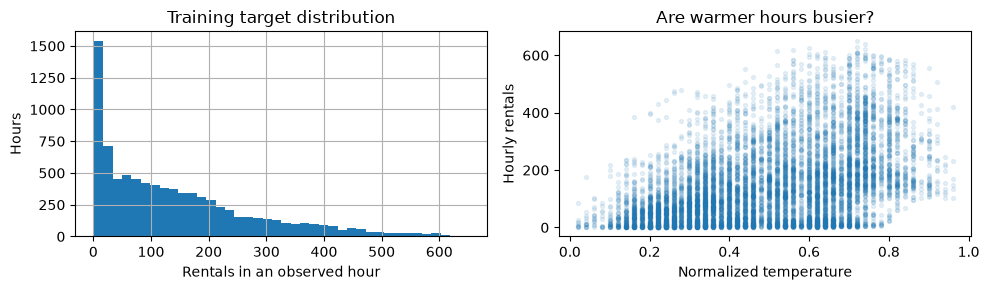

In [59]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
y.hist(bins=40, ax=axes[0])
axes[0].set(xlabel="Rentals in an observed hour", ylabel="Hours", title="Training target distribution")
axes[1].scatter(X["temp"], y, alpha=0.1, s=8)
axes[1].set(xlabel="Normalized temperature", ylabel="Hourly rentals",
            title="Are warmer hours busier?")

plt.tight_layout()
plt.show()

The target's distribution is rather skewed to the right and *zero-inflated**. Warmer hours tend to have more rentals, but temperature alone leaves substantial variation unexplained. 
<br>
Seaborn has an interesting function to display dependencies within and across several features at once. Let's examine this next.

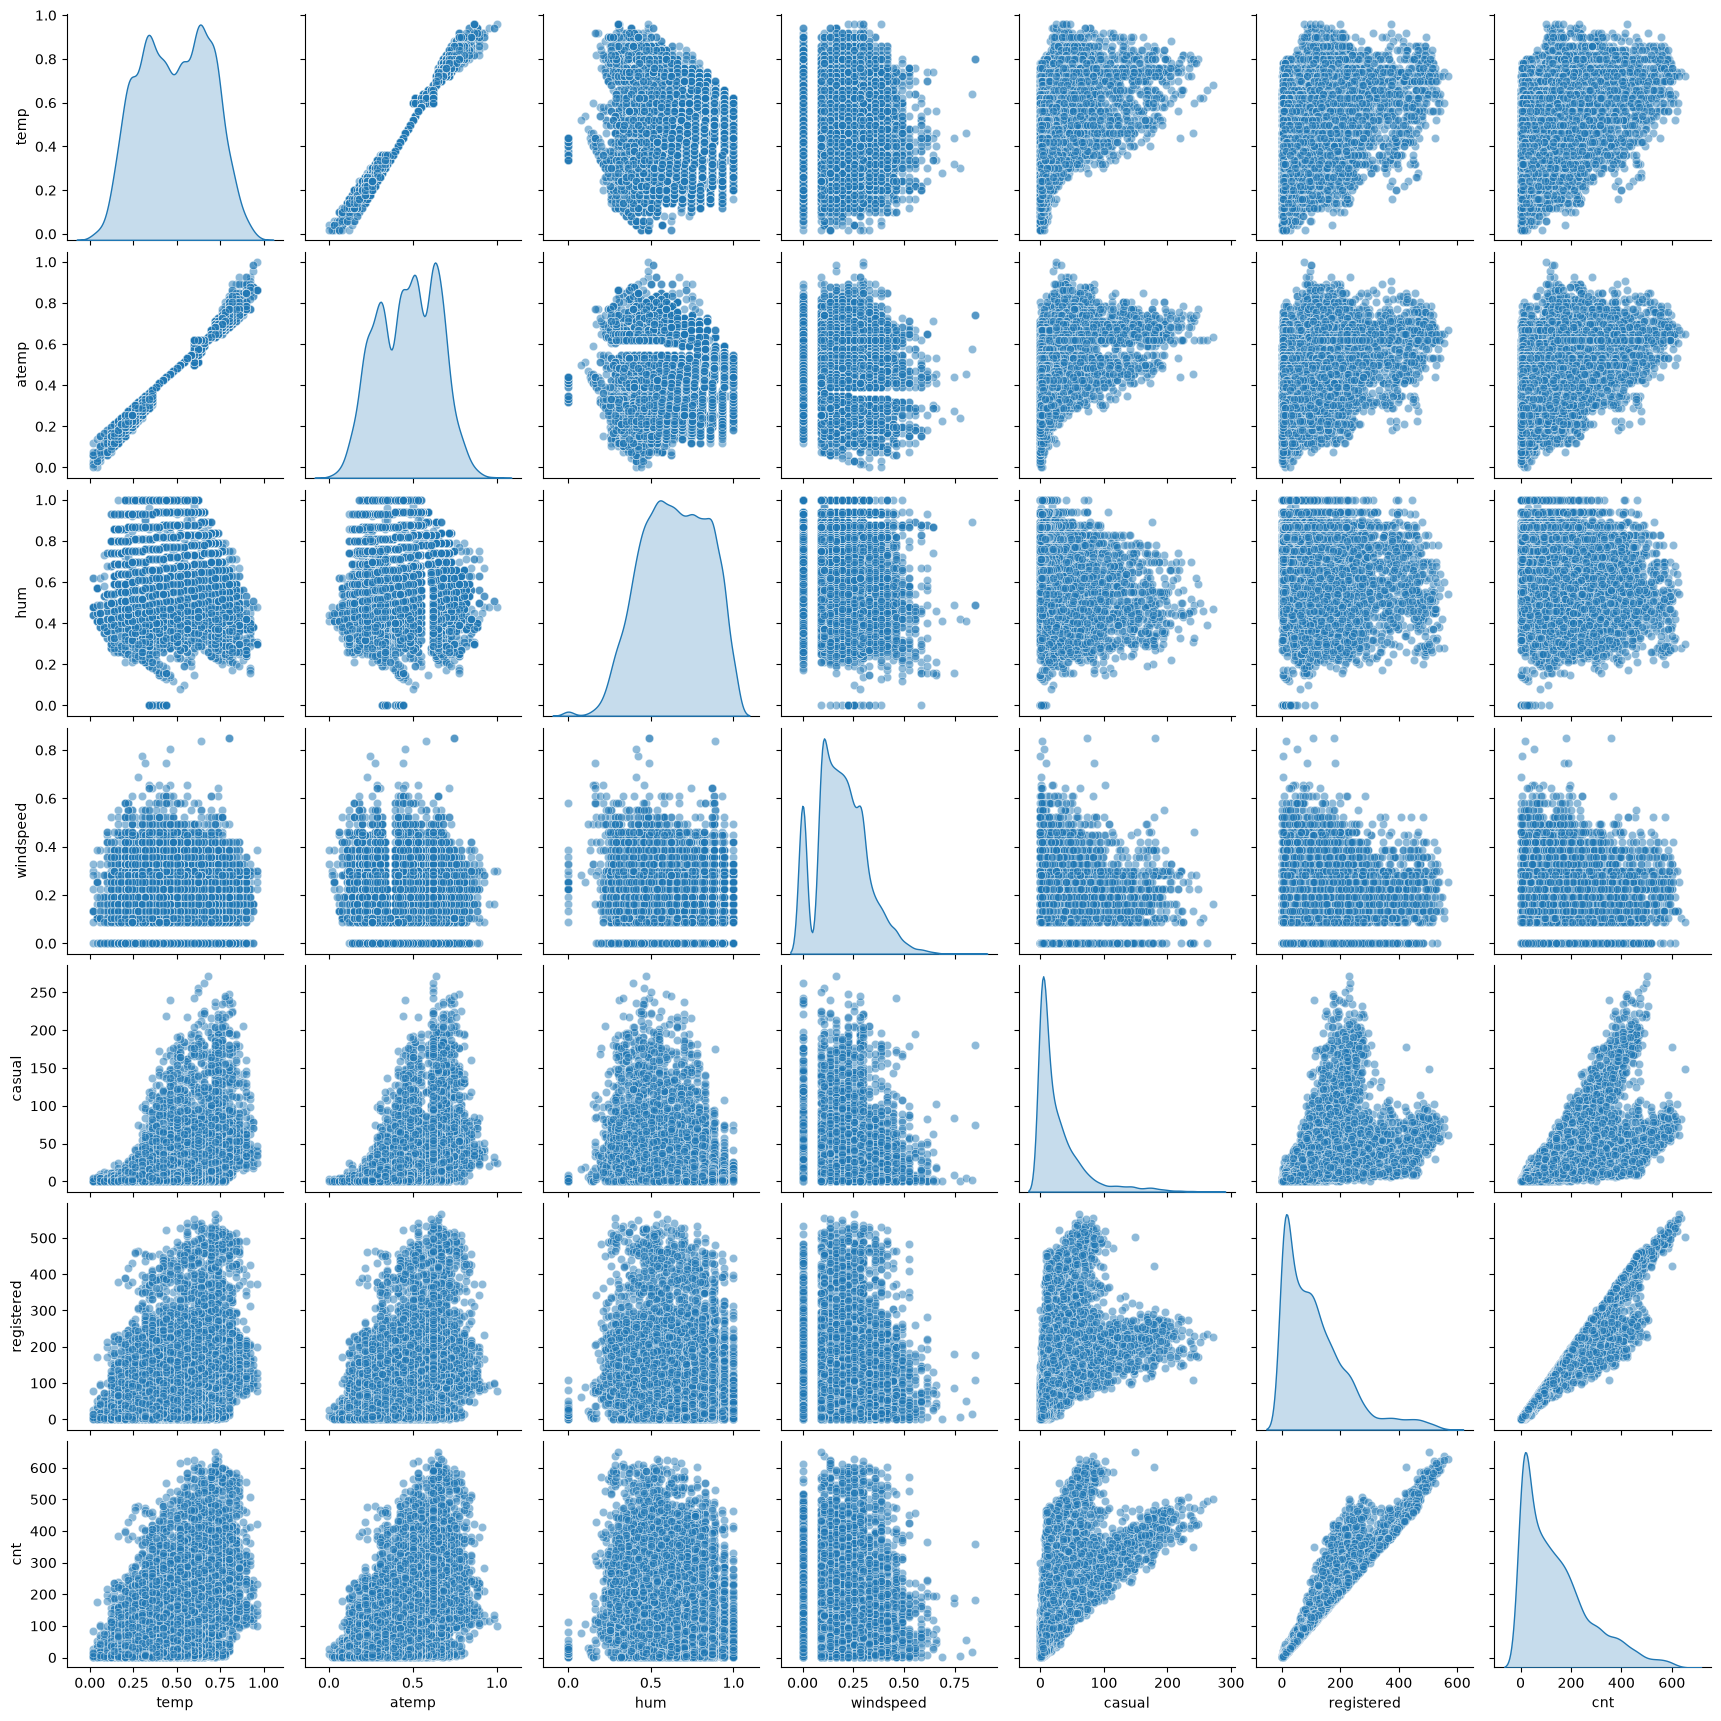

In [60]:

# Matrix of pairwise scatter plots for the numeric features in the training data. This is a useful way to visualize relationships between features and the target variable.
# numeric_features = X.select_dtypes(include=np.number).columns  # Try out this version to display all features
numeric_features = ["temp", "atemp", "hum", "windspeed", "casual", "registered"]
sns.pairplot(pd.concat([X[numeric_features], y], axis=1), diag_kind="kde", plot_kws={"alpha": 0.5})
plt.show()

A key insight you want to get from the **EDA** is that several features are internally stored as numbers but are not actually numbers or, put differently, should not be treated as numbers. This concerns `hr`, `mnth`, `weekday`, `season` and `weathersit`. Thus, it is important to check feature meanings before deciding how a feature enters your model.

In [61]:
display(X.info())  # reveal internal data storage

<class 'pandas.DataFrame'>
RangeIndex: 8645 entries, 0 to 8644
Data columns (total 14 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   season      8645 non-null   int64  
 1   yr          8645 non-null   int64  
 2   mnth        8645 non-null   int64  
 3   hr          8645 non-null   int64  
 4   holiday     8645 non-null   int64  
 5   weekday     8645 non-null   int64  
 6   workingday  8645 non-null   int64  
 7   weathersit  8645 non-null   int64  
 8   temp        8645 non-null   float64
 9   atemp       8645 non-null   float64
 10  hum         8645 non-null   float64
 11  windspeed   8645 non-null   float64
 12  casual      8645 non-null   int64  
 13  registered  8645 non-null   int64  
dtypes: float64(4), int64(10)
memory usage: 945.7 KB


None

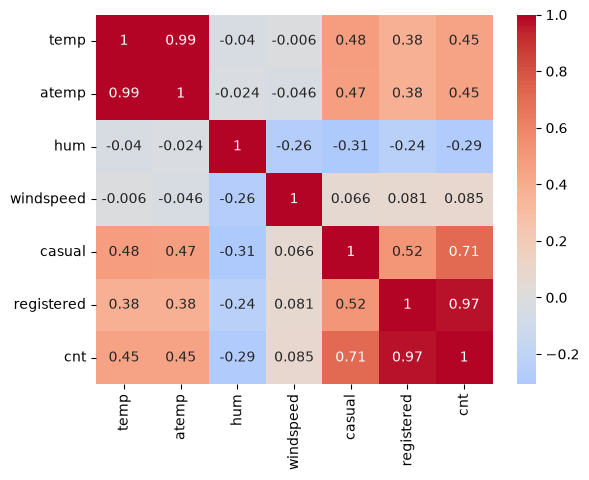

In [62]:
# Pairwise correlation matrix for the numeric features in the training data. This is a useful way to quantify relationships between features and the target variable.
correlation_matrix = pd.concat([X[numeric_features], y], axis=1).corr()
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm", center=0)
plt.show()

The correlation analysis reveals some very high correlations. Among these, further discussion is warranted for the correlation between the target and `casual` and `registered`. 

**Leakage:** `casual + registered = cnt`. These two counts are parts of the outcome. Their apparent explanatory power comes from knowing the answer already. So they must be excluded from regression models. To see this, consider the following, deliberately wrong model specification. Make sure to rerun a few times to study what happends if you include only one of the leaky features. 


LEAKY training R²: 1.0
LEAKY coefficients: [-1.02170090e-12  9.10379546e-13  1.57985896e-13 -3.01489049e-14
  1.00000000e+00  1.00000000e+00]


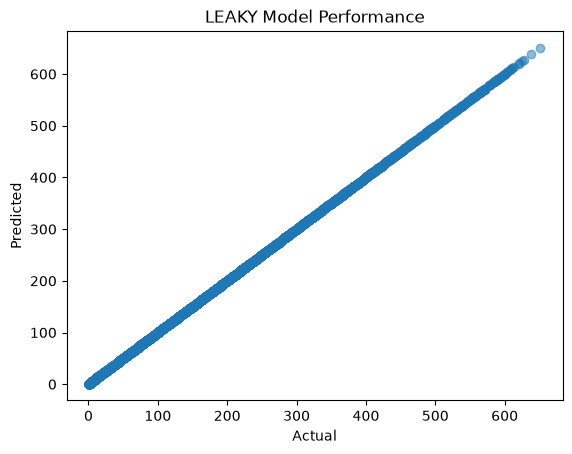

In [63]:
leaky_features = ["temp", "atemp", "hum", "windspeed", "casual", "registered"] # incl the leaky features

leaky = LinearRegression().fit(X[leaky_features], y)
print("LEAKY training R²:", leaky.score(X[leaky_features], y))
print("LEAKY coefficients:", leaky.coef_)

# scatter plot of the target variable against model estimates
plt.scatter(y, leaky.predict(X[leaky_features]), alpha=0.5)
plt.xlabel("Actual")
plt.ylabel("Predicted")
plt.title("LEAKY Model Performance")
plt.show()

### Solution 1B · Fit and interpret the continuous-feature model

Use `statsmodels` to obtain p-values and a regression summary. Add an intercept explicitly. For now, focus on **R²**, the **F-test** and the coefficient **p-values** in the summary; you can ignore the other diagnostics.

In [64]:
continuous = ["temp", "atemp", "hum", "windspeed"]
X_numeric = sm.add_constant(X[continuous])
numerical = sm.OLS(y, X_numeric).fit()
print(numerical.summary())

significant = numerical.pvalues[continuous] < 0.05
print("Significant continuous features at 5%:", significant[significant].index.tolist())
print("Correlation between temp and atemp:", round(X.temp.corr(X.atemp), 3))

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.279
Model:                            OLS   Adj. R-squared:                  0.278
Method:                 Least Squares   F-statistic:                     834.3
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:05:07   Log-Likelihood:                -53183.
No. Observations:                8645   AIC:                         1.064e+05
Df Residuals:                    8640   BIC:                         1.064e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const        101.3964      6.606     15.348      0.0

**Results for 2011:** the continuous-feature model explains about **28%** of rental variation (R² = 0.279). `atemp`, `hum` and `windspeed` have p-values below 0.05; `temp` does not (p ≈ 0.063). Humidity has a negative coefficient, while the other three coefficients are positive. This does not mean that warm-feeling temperature matters but measured temperature does not: the two features have a correlation of about 0.992 and largely describe the same information. The F-test p-value is very small, so the four predictors jointly improve on an intercept-only model.

**Read the model:** R² tells you what fraction of training variation the model explains. The F-test asks whether the predictors, taken together, improve on an intercept-only model. A coefficient p-value below 0.05 provides evidence of an association after accounting for the other included features, under the model assumptions.

The sign of a coefficient tells you the direction of that adjusted association. Because these weather measurements are normalized, a one-unit change does not mean one degree Celsius. `temp` and `atemp` are strongly correlated: interpreting a change in one while keeping the other fixed requires care. Statistical significance does not tell you the size of an effect or establish causality.

<details>
<summary><strong>Disclaimer</strong></summary>

Ordinary regression inference assumes independent errors with constant variance. Hourly rental errors may be correlated across nearby hours, and busy hours may have more variable errors. This can make ordinary p-values misleading. HAC standard errors allow unequal variances and nearby error correlation; they change uncertainty estimates, not coefficients or predictions. A 24-lag window is an illustration, not a universal choice. Missing hours mean 24 observations need not equal 24 elapsed hours.

Optional comparison:

```python
numerical_hac = sm.OLS(y, X_numeric).fit(
    cov_type="HAC", cov_kwds={"maxlags": 24}
)
display(pd.DataFrame({
    "Coefficient": numerical.params,
    "p-value (ordinary)": numerical.pvalues,
    "p-value (HAC)": numerical_hac.pvalues,
}))
```

</details>

### Solution 1C · Add categorical information

One-hot encoding gives each category its own adjustment. Drop one category per feature to provide a reference level alongside the intercept. Fit the encoder on training data only, and reuse it for test data later.

Exclude `yr`: it is always zero in 2011, so this training period cannot teach us a year effect. Also exclude `workingday`: in these observations it is determined by weekday and holiday, making its column redundant with those features and the intercept. Keep both month and season: some season boundaries fall within a month, so the two are not identical.

In [65]:
categorical = ["hr", "mnth", "weekday", "season", "weathersit"]
encoder = OneHotEncoder(drop="first", handle_unknown="ignore")
encoded = encoder.fit_transform(X[categorical]).toarray()
category_names = encoder.get_feature_names_out(categorical)

# Keep names so that the regression summary remains readable.
X_categories = pd.DataFrame(encoded, columns=category_names, index=X.index)
X_all = pd.concat([X_categories, X[["holiday"] + continuous]], axis=1)
full_model = sm.OLS(y, sm.add_constant(X_all)).fit()
print(full_model.summary())

display(pd.Series({"Continuous features": numerical.rsquared,
                   "With categories": full_model.rsquared}, name="Training R²").round(3))

                            OLS Regression Results                            
Dep. Variable:                    cnt   R-squared:                       0.685
Model:                            OLS   Adj. R-squared:                  0.683
Method:                 Least Squares   F-statistic:                     366.0
Date:                Thu, 12 Nov 2026   Prob (F-statistic):               0.00
Time:                        15:05:07   Log-Likelihood:                -49605.
No. Observations:                8645   AIC:                         9.931e+04
Df Residuals:                    8593   BIC:                         9.968e+04
Df Model:                          51                                         
Covariance Type:            nonrobust                                         
                   coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------
const          -22.6524      6.858     -3.303   

Continuous features    0.279
With categories        0.685
Name: Training R², dtype: float64

In [73]:
X_categories 

,hr_1,hr_2,hr_3,hr_4,hr_5,hr_6,hr_7,hr_8,hr_9,hr_10,...,weekday_3,weekday_4,weekday_5,weekday_6,season_2,season_3,season_4,weathersit_2,weathersit_3,weathersit_4
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
3,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8640,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8641,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8642,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
8643,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0


The categorical model raises training R² from **0.279 to 0.685**: it explains about 69% of observed training variation. In particular, hour dummies let the daily pattern rise and fall instead of forcing a straight line through the hours. `hr_8` compares 08:00 with reference hour 00:00, holding the other included features fixed. A negative humidity coefficient describes lower rentals at higher humidity after adjusting for the other features.

The summary's F-test evaluates the predictors together. A dummy's p-value compares one category with its reference; it does not test the whole categorical feature. Focus on the overall improvement here rather than counting significant dummies.

CityCycle can use these associations to discuss staffing and capacity. They do not show that changing a measured feature would cause the estimated change in demand. Also, adding predictors cannot reduce training R²: a better training fit still needs a forecast check.

## Discussion · Reporting back to Maya (20 min)

- Which patterns would you report to Maya, and what evidence supports them?
- Why would including `casual` and `registered` give a misleading result?
- What changed when you encoded the categories?
- Which conclusions describe associations, and which would require evidence about causes?

## Task 2 · Predict the next year (15 min)

Addressing our CEO's second request, we next turn to the 2012 data. More specifically, we will investigate how well our regression model from the previous part is able to predict 2012 rentals.

**Your task:**  Use the regression model from Task 1 to predict `y_test`. Assess R², RMSE and MAE. Compare with a constant prediction based on the *training* data. Compare training and test fit.

### Solution 2 · Forecast with LinearRegression

The question now concerns prediction, so switch to scikit-learn's `LinearRegression`. Use the same prepared features and reuse the training encoder. Fit every model on 2011 only.

Compare with a constant forecast equal to the **2011 mean**. R² compares squared errors with variation around the evaluated period's mean; negative test R² means you do worse than that period's mean. RMSE gives extra weight to large misses. MAE gives the average absolute miss, in rentals per hour.

In [66]:
encoded_test = encoder.transform(X_test[categorical]).toarray()
X_test_categories = pd.DataFrame(encoded_test, columns=category_names, index=X_test.index)
X_test_all = pd.concat([X_test_categories, X_test[["holiday"] + continuous]], axis=1)

regression = LinearRegression().fit(X_all, y)
fitted = regression.predict(X_all)
forecast = regression.predict(X_test_all)

# Reuse this small scoring function for the later comparisons.
def evaluate(name, training_prediction, test_prediction):
    return {"Model": name, "Train R²": r2_score(y, training_prediction),
            "Test R²": r2_score(y_test, test_prediction),
            "Test RMSE": np.sqrt(mean_squared_error(y_test, test_prediction)),
            "Test MAE": mean_absolute_error(y_test, test_prediction)}

results = [evaluate("Training mean", np.repeat(y.mean(), len(y)),
                    np.repeat(y.mean(), len(y_test))),
           evaluate("Regression with weather", fitted, forecast)]
display(pd.DataFrame(results).set_index("Model").round(3))

,Train R²,Test R²,Test RMSE,Test MAE
Model,,,,
Training mean,0.000,-0.189,227.808,168.252
Regression with weather,0.685,0.428,157.994,110.161


## Discussion · Forecasting accuracy and feasibility (15 min)

The recorded-weather model uses weather measured during 2012. Could you have known those values at the end of 2011? This is a benchmark with information from the future, rather than a feasible forecast of the whole next year. To evaluate weather-based forecasts, you would need weather forecasts available at the intended prediction time.

Try a calendar-only model using dates and holidays known in advance. Keep the same training/test split so you can compare the information sets.

,Train R²,Test R²,Test RMSE,Test MAE
Model,,,,
Training mean,0.000,-0.189,227.808,168.252
Regression with weather,0.685,0.428,157.994,110.161
Regression w/o weather,0.649,0.365,166.474,118.445


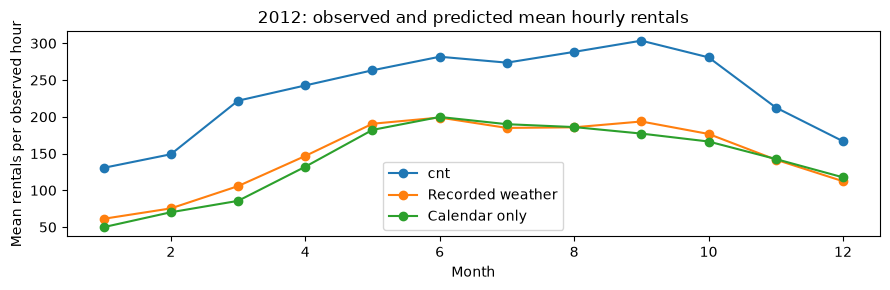

In [67]:
# Remove the weather dummies and continuous weather measurements.
calendar_columns = [c for c in X_all.columns
                    if c not in continuous and not c.startswith("weathersit_")]
X_calendar = X_all[calendar_columns]
X_test_calendar = X_test_all[calendar_columns]
calendar_model = LinearRegression().fit(X_calendar, y)
calendar_fitted = calendar_model.predict(X_calendar)
calendar_forecast = calendar_model.predict(X_test_calendar)
results.append(evaluate("Regression w/o weather", calendar_fitted, calendar_forecast))
display(pd.DataFrame(results).set_index("Model").round(3))

# Monthly averages reveal persistent errors that a single score can hide.
monthly = test[["dteday", "cnt"]].copy()
monthly["Recorded weather"] = forecast
monthly["Calendar only"] = calendar_forecast
monthly.groupby(monthly.dteday.dt.month)[["cnt", "Recorded weather", "Calendar only"]].mean().plot(
    figsize=(9, 3), marker="o")
plt.title("2012: observed and predicted mean hourly rentals")
plt.xlabel("Month")
plt.ylabel("Mean rentals per observed hour")
plt.tight_layout()
plt.show()

### What do the forecasts tell CityCycle?

The recorded-weather model achieves test R² **0.428** and MAE **110.2 rentals/hour**, compared with R² **0.365** and MAE **118.4** for the calendar-only model. Both improve on the training-mean forecast (MAE **168.3**). Weather information helps describe recorded rentals, but it does not remove the gap between training fit and next-year performance. The monthly plot shows whether errors persist across seasons. Rentals grew between 2011 and 2012, and a model trained on 2011 cannot estimate that growth from the constant `yr` feature. The calendar-only forecast is available in advance, but it cannot adapt to unusual weather or changes in the service.

Keep this test year for evaluation. If you use its results to choose new features or models, you will need a new test period to assess your final choice.

## Demos · Can separate regressions capture different patterns?

### Two daily rental profiles

These curves summarize two groups of **2011 training observations**. What differences do you notice? What could explain these differences? 

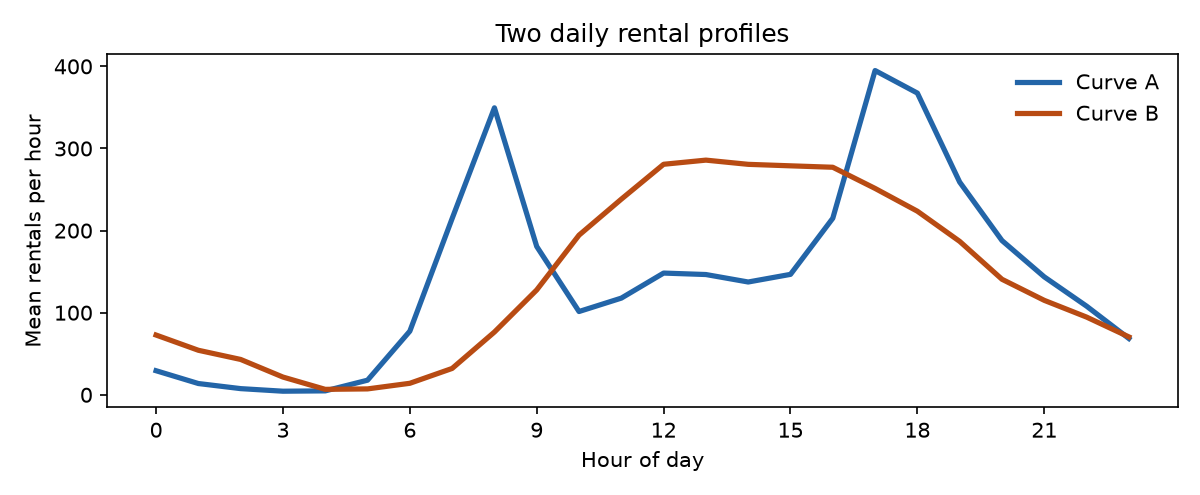

### Demo 1 · Use calendar knowledge to form three groups

The profiles suggest that one shared set of coefficients may miss different daily patterns. Fit three calendar-only regressions:

- **Nighttime:** 00:00–05:59 on every day.
- **Daytime weekday:** 06:00–23:59, Monday–Friday.
- **Daytime non-weekday:** 06:00–23:59, Saturday–Sunday.

Here, weekday means Monday–Friday, including holidays. This differs from the dataset's `workingday` flag. Assign nighttime first so the groups never overlap. Fix these rules before evaluating the models. Use the same calendar features as the single model for a fair comparison.

In [68]:
def day_segments(frame):
    groups = pd.Series("Daytime non-weekday", index=frame.index)
    groups.loc[frame["weekday"].between(1, 5)] = "Daytime weekday"
    groups.loc[frame["hr"] < 6] = "Nighttime"
    return groups

train_groups = day_segments(train)
test_groups = day_segments(test)
display(pd.DataFrame({"Training hours": train_groups.value_counts(),
                      "Test hours": test_groups.value_counts()}))

# Fit on each training group, then route test rows to the matching model.
# Reuse the training-encoded calendar matrices: do not fit another encoder on test data.
def fit_segments(training_groups, testing_groups):
    training_prediction = pd.Series(index=train.index, dtype=float)
    test_prediction = pd.Series(index=test.index, dtype=float)
    for group in training_groups.unique():
        tr = training_groups == group
        te = testing_groups == group
        model = LinearRegression().fit(X_calendar.loc[tr], y.loc[tr])
        training_prediction.loc[tr] = model.predict(X_calendar.loc[tr])
        test_prediction.loc[te] = model.predict(X_test_calendar.loc[te])
    return training_prediction, test_prediction

domain_fitted, domain_forecast = fit_segments(train_groups, test_groups)
demo_results = [evaluate("One calendar regression", calendar_fitted, calendar_forecast),
                evaluate("Three calendar segments", domain_fitted, domain_forecast)]
display(pd.DataFrame(demo_results).set_index("Model").round(3))

,Training hours,Test hours
Daytime weekday,4658,4673
Nighttime,2105,2171
Daytime non-weekday,1882,1890


,Train R²,Test R²,Test RMSE,Test MAE
Model,,,,
One calendar regression,0.649,0.365,166.474,118.445
Three calendar segments,0.807,0.503,147.271,104.859


Separate models can learn different hour effects and different coefficients for each group. Each model remains linear in its coefficients, but the combined prediction rule can adapt to different parts of the week and day. Hour dummies already allow peaks and dips; segmentation additionally lets their sizes change across groups.

Compare overall training R² and test errors in the table. Compute these from the combined predictions, rather than averaging group R² values. Smaller groups give each model fewer observations, so improved training fit does not guarantee better forecasts.

**On this split**, the three models raise training R² from **0.649 to 0.807** and test R² from **0.365 to 0.503**. Test MAE falls from **118.4 to 104.9 rentals/hour**. The groups help on future observations as well as training data, though substantial errors remain.

### Demo 2 · Let K-means form the groups

Instead of writing calendar rules, use K-means to group similar inputs and fit one regression per cluster. Use four clusters for this example. K-means sees the hour and whether the day is Monday–Friday; it never sees rental counts or future weather.

Represent hour with sine and cosine so 23:00 and 00:00 are close together. Keep both coordinates on the same scale and use a 0/1 weekday indicator. These choices define what “similar” means. Fit the cluster centers on 2011, then assign 2012 rows to those same centers.

,Train R²,Test R²,Test RMSE,Test MAE
Model,,,,
One calendar regression,0.649,0.365,166.474,118.445
Three calendar segments,0.807,0.503,147.271,104.859
K-means + regression,0.762,0.450,154.917,108.955


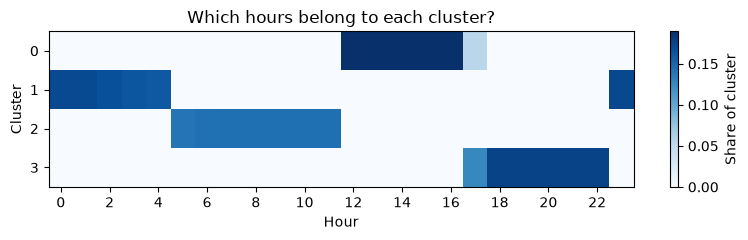

In [69]:
def cluster_inputs(frame):
    angle = 2 * np.pi * frame["hr"] / 24
    return pd.DataFrame({"hour_sin": np.sin(angle), "hour_cos": np.cos(angle),
                         "weekday": frame["weekday"].between(1, 5).astype(int)},
                        index=frame.index)

kmeans = KMeans(n_clusters=4, n_init=10, random_state=42)
train_clusters = pd.Series(kmeans.fit_predict(cluster_inputs(train)), index=train.index)
test_clusters = pd.Series(kmeans.predict(cluster_inputs(test)), index=test.index)
cluster_fitted, cluster_forecast = fit_segments(train_clusters, test_clusters)
demo_results.append(evaluate("K-means + regression", cluster_fitted, cluster_forecast))
display(pd.DataFrame(demo_results).set_index("Model").round(3))

# Inspect the learned groups; cluster numbers are arbitrary labels.
cluster_hours = pd.crosstab(train_clusters, train["hr"], normalize="index")
fig, ax = plt.subplots(figsize=(8, 2.5))
im = ax.imshow(cluster_hours, aspect="auto", cmap="Blues")
ax.set(title="Which hours belong to each cluster?", xlabel="Hour", ylabel="Cluster",
       xticks=range(0, 24, 2), yticks=range(4))
fig.colorbar(im, ax=ax, label="Share of cluster")
plt.tight_layout()
plt.show()

### Compare the forecast errors

A score can hide repeated misses at particular hours. Plot mean actual minus predicted rentals for each hour, separately for weekdays and weekends. Values above zero indicate underprediction; values below zero indicate overprediction.

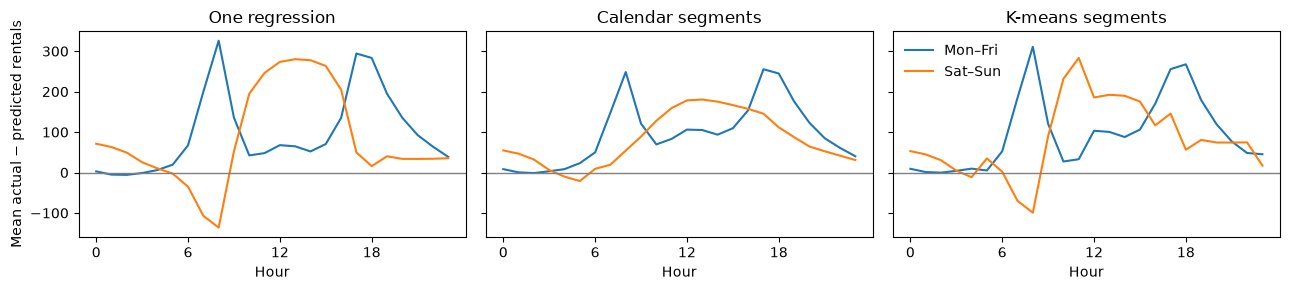

In [70]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3), sharey=True)
for ax, name, prediction in zip(axes,
        ["One regression", "Calendar segments", "K-means segments"],
        [calendar_forecast, domain_forecast, cluster_forecast]):
    errors = test[["hr", "weekday"]].copy()
    errors["Weekday"] = errors["weekday"].between(1, 5)
    errors["Error"] = y_test - prediction
    profiles = errors.groupby(["hr", "Weekday"])["Error"].mean().unstack()
    ax.plot(profiles.index, profiles[True], label="Mon–Fri")
    ax.plot(profiles.index, profiles[False], label="Sat–Sun")
    ax.axhline(0, color="gray", lw=1)
    ax.set(title=name, xlabel="Hour", xticks=range(0, 24, 6))
axes[0].set_ylabel("Mean actual − predicted rentals")
axes[-1].legend(frameon=False)
plt.tight_layout()
plt.show()

### What did we learn?

**On this split**, K-means regression reaches training R² **0.762**, test R² **0.450** and test MAE **109.0 rentals/hour**. It improves on one calendar regression but trails the three calendar segments.

K-means groups similar inputs, not observations with similar forecast errors. Its clusters may mostly divide the clock into time windows rather than distinguish the two daily profiles. The heatmap helps you inspect that choice. Domain knowledge can create more useful groups, but neither approach guarantees an improvement on a new period.

The forecast-error plots show which daily patterns remain unexplained. All three approaches can still miss next-year growth and unusual conditions. OLS also permits negative predictions: it does not enforce the nonnegative nature of counts.

Use the results to ask a practical question: does extra complexity reduce errors enough to help CityCycle? Choose group boundaries or the number of clusters using earlier time-ordered validation periods, then evaluate the final choice on a fresh test period.